<img src="./logo_UTN.svg" align="right" width="150" /> 

#### Teoría de los Circuitos 2

# **Informe de Laboratorio 2**
#### Nahuel Siles

<img src="Circuito.PNG" width="500"/>

**Librería CMSIS:**

El filtro digital en sí mismo es un algoritmo. En nuestro caso para simplificar la tarea vamos a instanciar funciones de la librería de procesamiento digital de arm cmis-dsp:

* arm_fir_f32 
* arm_biquad_cascade_df1_f32

El IDE para trabajar con el mcu es el **STM32CubeIDE**

## Plantillas:
<img src="Plantillas.PNG"/>

## Análisis y Simulación ( Pre-Lab )

* Obtener los coeficientes del filtro digital usando la función iirdesign
* Simulación de la función transferencia en Python para una frecuencia de sampling configurable.

## Implementación ( STM32 )
* Compilar sin errores el proyecto en el IDE.

## Medición ( In-Lab )
Las conexiones con el kit de desarrollo se detallan a continuación:

<img src="Pines.PNG"/>

In [4]:
# Módulos numéricos y de funciones científicas
import numpy as np
from scipy import signal as sig
import sympy as sp
from IPython.display import display, Math

# Módulos para los gráficos
import matplotlib as mpl
from matplotlib import pyplot as plt

# Funciones de PyTC2
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys, tf2sos_analog, pretty_print_SOS, plot_plantilla
from pytc2.general import print_latex, print_subtitle, a_equal_b_latex_s

#Tamaño de los gráficos
fig_sz_x = 13
fig_sz_y = 7
fig_dpi = 80 # dpi

fig_font_size = 11

mpl.rcParams['figure.figsize'] = (fig_sz_x, fig_sz_y)
mpl.rcParams['figure.dpi'] = fig_dpi
plt.rcParams.update({'font.size':fig_font_size})

### **Análisis y Simulación**

Para obtener los coeficientes de los filtros IIR utilizamos la función presente en *scipy signal* llamada ***iirdesign***

#### **Pasabajos IIR**

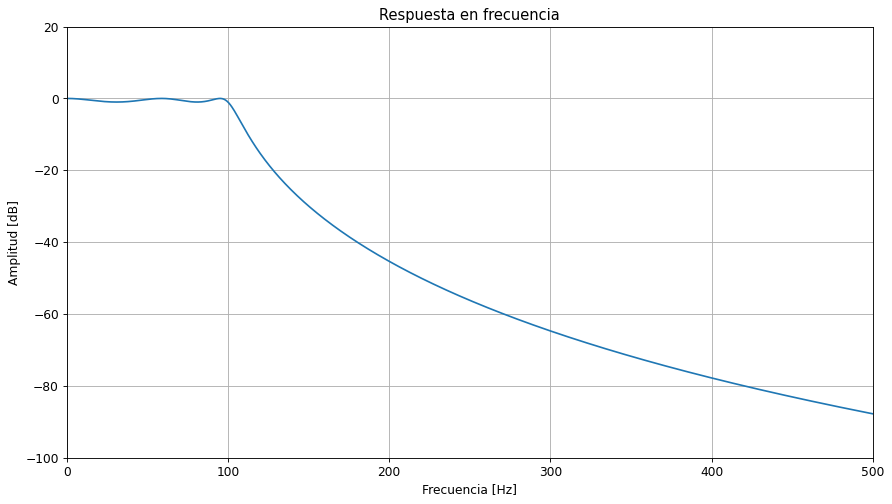

In [63]:
#Parametros de Plantilla
fpass = 100
fstop = 300
atte = 60
ripple = 1

#Parametros Digitales
fs=20000   #Frecuencia de muestreo
npoints = 20000   #Puntos para graficar 

#Coeficientes sin normalizar
num , den = sig.iirdesign( fpass, fstop, ripple, atte, ftype = "cheby1", fs=fs)

#Respuesta en frecuencia
w, h = sig.freqz( num, den, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

plt.figure()
plt.plot(w, modh)
plt.title('Respuesta en frecuencia')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.xlim(0,500)
plt.ylim(-100,20)
plt.grid(which='both', axis='both')

Los coeficientes **b** y **a** son:

In [39]:
print("Los coeficientes b son:")
for i, b in enumerate(num):
    print(f"b{i} = {b}")

print("\nLos coeficientes a son:")
for i, a in enumerate(den):
    print(f"a{i} = {a}")

Los coeficientes b son:
b0 = 1.1575662986526186e-10
b1 = 5.787831493263093e-10
b2 = 1.1575662986526186e-09
b3 = 1.1575662986526186e-09
b4 = 5.787831493263093e-10
b5 = 1.1575662986526186e-10

Los coeficientes a son:
a0 = 1.0
a1 = -4.969340590551355
a2 = 9.879050066643295
a3 = -9.821075763649615
a4 = 4.882364256079237
a5 = -0.9709979648173488


Vemos por la cantidad de coeficientes ***a***-1, que es un filtro de quinto orden.

#### **Notch IIR**

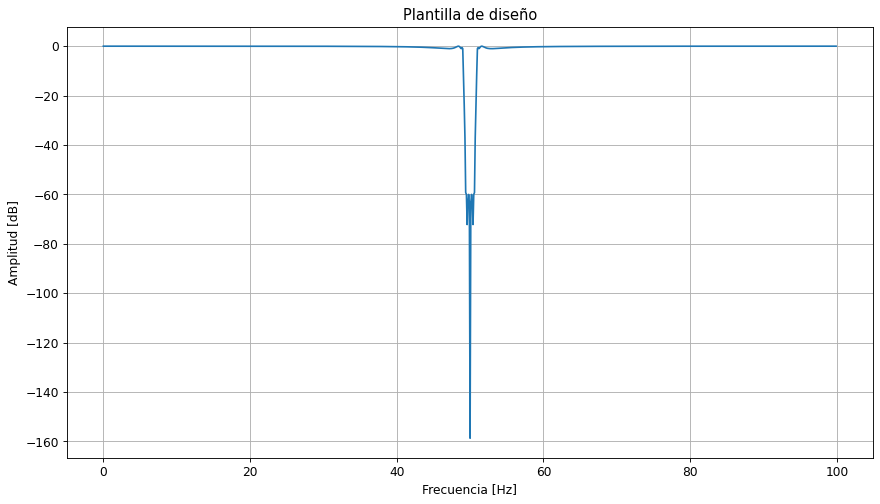

In [58]:
#Parametros Plantilla
fnotch = 50 
bw = 1
ripple = 1
atte = 60

#Parametros Digitales
fs=200   #Frecuencia de muestreo
npoints = 1000    #Puntos para graficar 

#Frecuencias de corte
fmin = fnotch - bw/2
fmax = fnotch + bw/2

#Frecuencias de paso
fpmin = (fmin - bw/2)
fpmax = (fmax + bw/2)

#Coeficientes
num , den = sig.iirdesign( [fpmin ,fpmax ], [fmin, fmax], ripple, atte, fs=fs)

#Respuesta en frecuencia
w, h = sig.freqz( num, den, npoints, fs=fs)
modh = 20*np.log10(np.abs(h))

plt.plot(w, modh)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')

Los coeficientes **b** y **a** son:

In [59]:
print("Los coeficientes b son:")
for i, b in enumerate(num):
    print(f"b{i} = {b}")

print("\nLos coeficientes a son:")
for i, a in enumerate(den):
    print(f"a{i} = {a}")

Los coeficientes b son:
b0 = 0.8798544276706456
b1 = -4.2954086377813595e-07
b2 = 4.397632227283566
b3 = -1.7176830701369753e-06
b4 = 8.793625186313765
b5 = -2.5762844755116836e-06
b6 = 8.793625186313767
b7 = -1.717683070149186e-06
b8 = 4.3976322272835695
b9 = -4.2954086377203085e-07
b10 = 0.8798544276706456

Los coeficientes a son:
a0 = 1.0
a1 = -4.759050523175934e-07
a2 = 4.746432972253049
a3 = -1.8071252067819454e-06
a4 = 9.011901565465246
a5 = -2.57323719959901e-06
a6 = 8.55454631018053
a7 = -1.6282370692011217e-06
a8 = 4.059212967256685
a9 = -3.862278070906888e-07
a10 = 0.7701298673804593


#### **Pasabajos FIR**

Para el filtro FIR utilizamos la función presente en *scipy signal* llamada ***firwin***

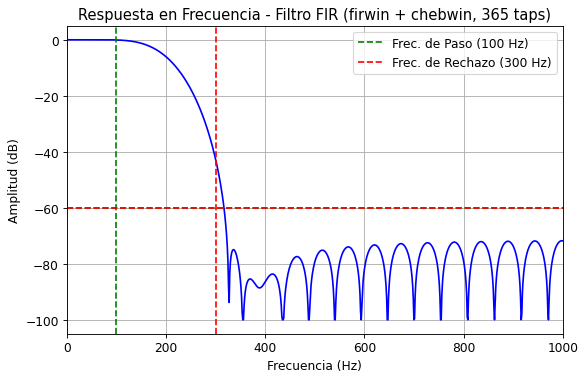

In [74]:
#Parametros de plantilla
fpass = 100.0     
fstop = 300.0  
ripple = 1.0     
atte = 60.0    

#Parametros digitales
fs = 20000.0  
nyq = 0.5 * fs_muestreo # Frecuencia de Nyquist

# 3. Calcular parámetros para firwin
# La frecuencia de corte se ubica típicamente en el centro de la banda de transición
fc = (fp + f_stop) / 2.0 

# Estimamos el número de coeficientes necesarios
ancho_transicion = (fstop - fpass) / nyq
num_taps, beta = sig.kaiserord(atte, ancho_transicion)

# Forzamos que el número de taps sea impar (ideal para filtros FIR pasa bajos fase lineal)
if num_taps % 2 == 0:
    num_taps += 1

# 4. Diseñar el filtro usando firwin
# Usamos una ventana de Chebyshev ('chebwin') ajustada a los 60 dB de rechazo
taps_fir = sig.firwin(num_taps, fc, window=('chebwin', atte), fs=fs)

#501 ajusta bien

# --- Opcional: Graficar la respuesta en frecuencia ---
w, h = sig.freqz(taps_fir, worN=8000, fs=fs)
plt.figure(figsize=(8, 5))
plt.plot(w, 20 * np.log10(np.maximum(abs(h), 1e-5)), 'b')
plt.title(f'Respuesta en Frecuencia - Filtro FIR (firwin + chebwin, {num_taps} taps)')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud (dB)')
plt.axvline(fp, color='green', linestyle='--', label='Frec. de Paso (100 Hz)')
plt.axvline(fstop, color='red', linestyle='--', label='Frec. de Rechazo (300 Hz)')
plt.axhline(-atte, color='green', linestyle='--')
plt.axhline(-atte, color='red', linestyle='--')
#plt.ylim(-80, 5)
plt.xlim(0, 1000)
plt.legend()
plt.grid(True)
plt.show()

Los coeficientes se muestran a continuación de forma tal que se pueda copiar y pegar en el IDE. Tambien se muestra la cantidad de coeficientes utilizados.

In [75]:
print("Cantidad de coeficientes utilizados:", num_taps)

Cantidad de coeficientes utilizados: 365


In [76]:
print(f"// Recuerda cambiar #define FIR_TAP_NUM a {num_taps} en filter.h")
print("float32_t float_fir_taps[FIR_TAP_NUM] = {")
print("    " + ", ".join([f"{t:.6f}f" for t in taps_fir]))
print("};\n")

// Recuerda cambiar #define FIR_TAP_NUM a 365 en filter.h
float32_t float_fir_taps[FIR_TAP_NUM] = {
    -0.000149f, -0.000025f, -0.000027f, -0.000030f, -0.000033f, -0.000036f, -0.000039f, -0.000042f, -0.000045f, -0.000048f, -0.000050f, -0.000053f, -0.000056f, -0.000058f, -0.000060f, -0.000062f, -0.000063f, -0.000064f, -0.000065f, -0.000065f, -0.000065f, -0.000064f, -0.000062f, -0.000060f, -0.000057f, -0.000053f, -0.000048f, -0.000042f, -0.000036f, -0.000028f, -0.000020f, -0.000011f, 0.000000f, 0.000012f, 0.000024f, 0.000038f, 0.000053f, 0.000069f, 0.000085f, 0.000103f, 0.000122f, 0.000142f, 0.000163f, 0.000184f, 0.000206f, 0.000229f, 0.000252f, 0.000276f, 0.000300f, 0.000324f, 0.000348f, 0.000372f, 0.000396f, 0.000419f, 0.000442f, 0.000464f, 0.000484f, 0.000504f, 0.000522f, 0.000538f, 0.000553f, 0.000565f, 0.000576f, 0.000583f, 0.000588f, 0.000590f, 0.000588f, 0.000584f, 0.000575f, 0.000563f, 0.000547f, 0.000527f, 0.000502f, 0.000474f, 0.000440f, 0.000402f, 0.000359f, 0.000311f, 0.0002

### **Implementación**

Para implementar introducimos los coeficientes de cada filtro y se descomenta el tipo de filtro a utilizar.

Además de cargar los coeficientes debemos realizar dos filtros pasabajos RC con frecuencia de corte en $10kHz$. Debe ir uno a la entrada y otro a la salida para limpiar el ruido de entrada y salida.

<img src="PasabajosRC.PNG"/>

### **Medición**

Las mediciones mediante el analizador de espectro arrojaron los siguientes graficos:

#### **Señal de offset**

<img src="offset.jpeg"/>

La señal entra y sale del microcontrolador sin cambios.

#### **Pasabajos IIR**

<img src="PasabajosIIR.jpeg"/>

Vemos que el filtro respeta y cumple aproximadamente con la plantilla:

* En la banda de paso se ve el ripple de un cheby.
* En $f=100Hz$ hay aproximadamente $0dB$.
* En $f=300Hz$ hay una atenuación de aproximadamente $60dB$.

#### **Pasaabajos FIR**

<img src="PasabajosFIR.jpeg"/>

Vemos que no cumple con la plantilla. Esto se debe a la poca cantidad de coeficientes utilizados.

* En $f=100Hz$ hay aproximadamente $2.5dB$.
* En $f=300Hz$ hay una atenuación de aproximadamente $31dB$ justo donde empiezan los picos.

#### **Notch IIR**

<img src="NotchIIR.jpeg"/>

El filtro practicamente elimina los $50Hz$ pedidos de la plantilla respetando tambien el ancho de banda de $1Hz$ atenuando aproximadamente $3dB$

[1.02444900e-05 5.12224498e-05 1.02444900e-04 1.02444900e-04
 5.12224498e-05 1.02444900e-05]
[ 1.         -4.5878723   8.53992135 -8.05601007  3.84945626 -0.74516742]


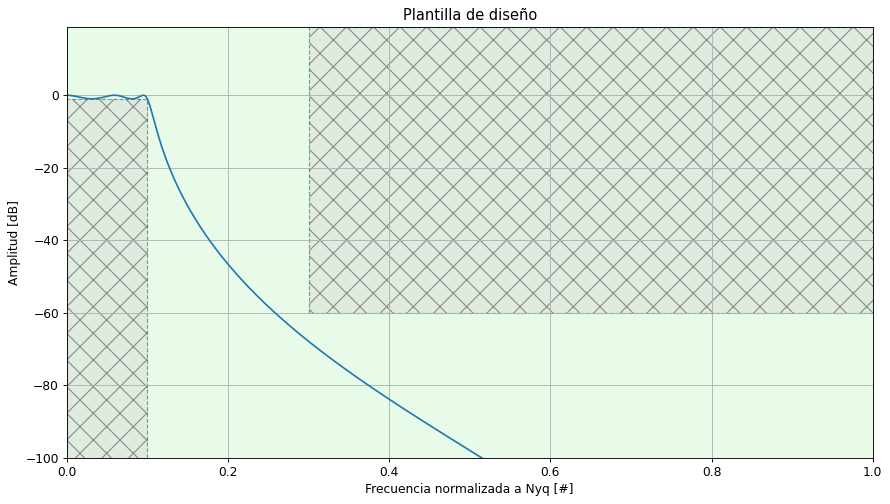

In [52]:
fpass = 100
fstop = 300
atte = 60
ripple = 1
fs=2000
fN = fs/2
npoints = 1000

wpass = fpass/fN
wstop = fstop/fN

num , den = sig.iirdesign( wpass, wstop, ripple, atte, ftype = "cheby1")

print(num)
print(den)

filtro = sig.TransferFunction(num,den, dt=1/fs)
w, mod, _ = filtro.bode(npoints)


w_nyq = 2*np.pi*fN

plt.figure()
plt.plot(w/w_nyq, mod)
plt.title('Plantilla de diseño')
plt.xlabel('Frecuencia normalizada a Nyq [#]')
plt.ylabel('Amplitud [dB]')
plt.grid(which='both', axis='both')

plt.gca().set_xlim([0,1])
plot_plantilla( filter_type='lowpass', fpass=fpass/fN, ripple=ripple, fstop=fstop/fN, attenuation=atte, fs=fs )